# Flight Fare Prediction

## 1. Problem Statement

Create a predictive model which will help the customers to predict future flight prices and plan their journey accordingly.

## 2. Business Objective

Flight ticket prices can be something hard to guess, today we might see a price, check out the price of the same flight tomorrow, it will be a different story. We might have often heard travelers saying that flight ticket prices are so unpredictable. That’s why we will try to use machine learning to solve this problem. This can help airlines by predicting what prices they can maintain. 

## 3. Dataset Description


Airline: So this column will have all the types of airlines like Indigo, Jet Airways, Air India, and many more.

Date_of_Journey: It will let us know about the date on which the passenger’s journey will start.

Source: This column holds the name of the place from where the passenger’s journey will start.

Destination: This column holds the name of the place to where passengers wanted to travel.

Route: It tells us about the route through which passengers opted to travel from source to destination.

Arrival_Time: Arrival time is when the passenger will reach his/her destination.

Duration: It is the whole period that a flight will take to complete its journey from source to destination.

Total_Stops: It tells us in how many places flights will stop there for the flight in the whole journey.

Additional_Info: In this column, we will get information about food, kind of food, and other amenities.

Price: Price of the flight for a complete journey including all the expenses before onboarding.

## 4. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 5. Data Loading

In [2]:
data = pd.read_excel('Flight_Fare.xlsx')

## 6. Initial Data Exploration

In [3]:
data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [4]:
data.shape

(10683, 11)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [6]:
data.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [7]:
data.describe(include='object')

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
count,10683,10683,10683,10683,10682,10683,10683,10683,10682,10683
unique,12,44,5,6,128,222,1343,368,5,10
top,Jet Airways,18/05/2019,Delhi,Cochin,DEL → BOM → COK,18:55,19:00,2h 50m,1 stop,No info
freq,3849,504,4537,4537,2376,233,423,550,5625,8345


## 7. Data Cleaning

In [8]:
data.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [9]:
data.duplicated().sum()

np.int64(220)

In [10]:
data[data["Route"].isnull()]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [11]:
data = data.dropna()
data = data.drop_duplicates()

In [12]:
print(data.shape)
print(data.isnull().sum().sum())
print(data.duplicated().sum())

(10462, 11)
0
0


## Data Cleaning Summary

Missing values were identified in the Route and Total_Stops columns and were removed. Duplicate records were also removed to avoid repeated observations during analysis and model training.

After cleaning, the dataset contains 10,462 rows and 11 columns.

## 8. Exploratory Data Analysis

<Axes: xlabel='Price', ylabel='Count'>

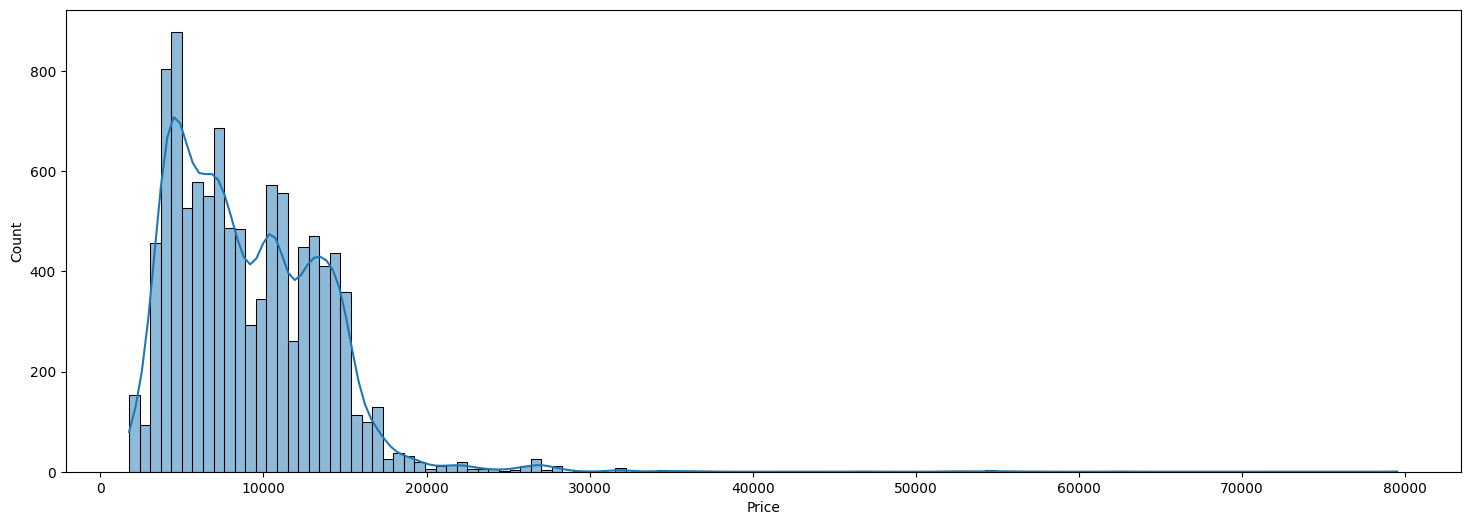

In [13]:
plt.figure(figsize=(18, 6))
sns.histplot(data=data, x='Price', kde=True)

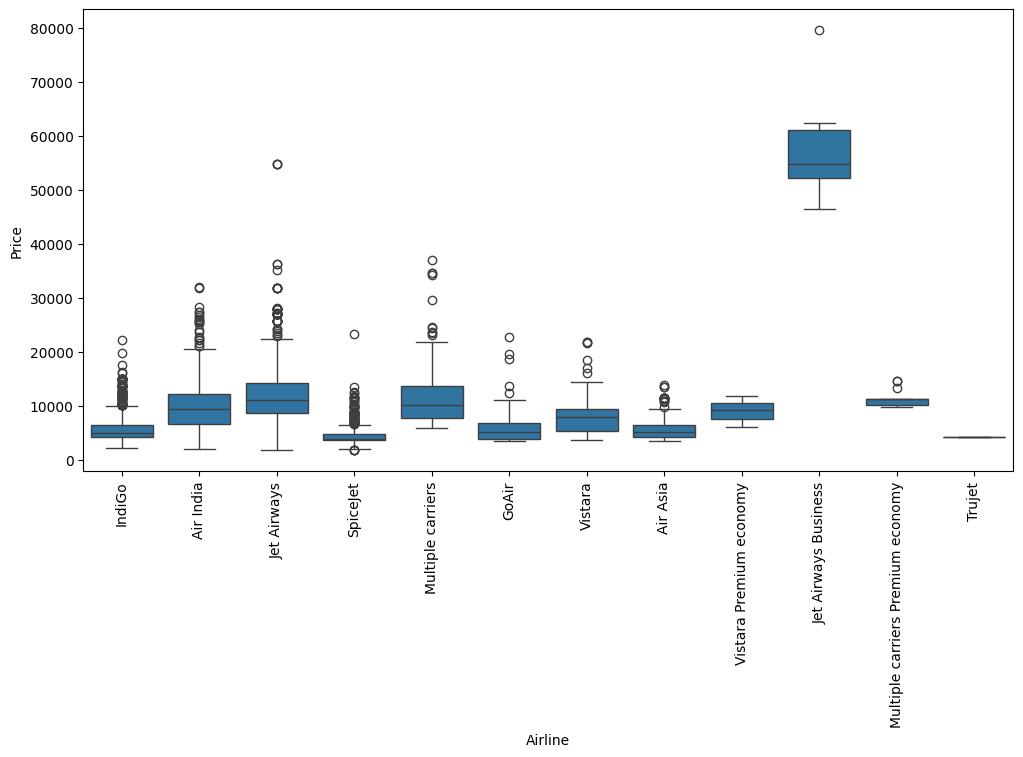

In [14]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='Airline', y='Price')
plt.xticks(rotation=90)
plt.show()

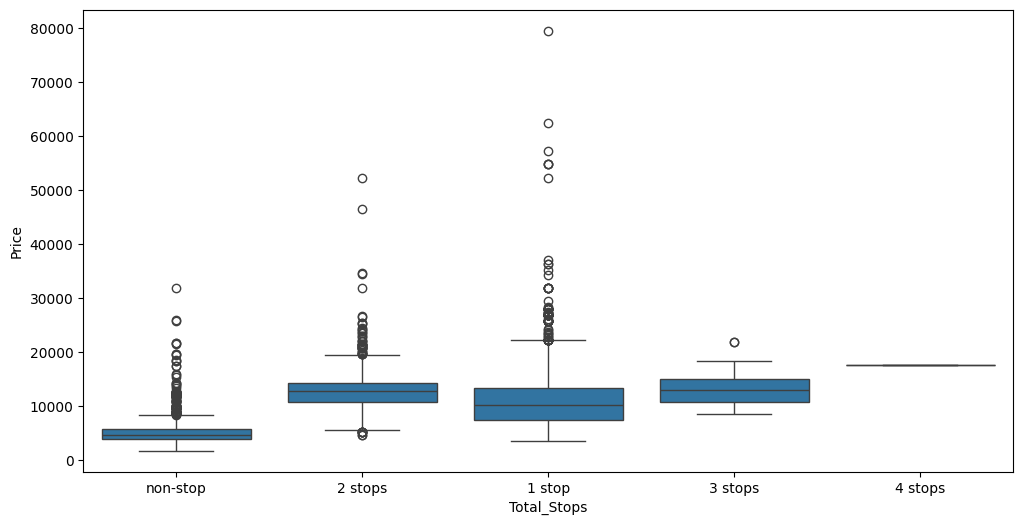

In [15]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='Total_Stops', y='Price')
plt.show()

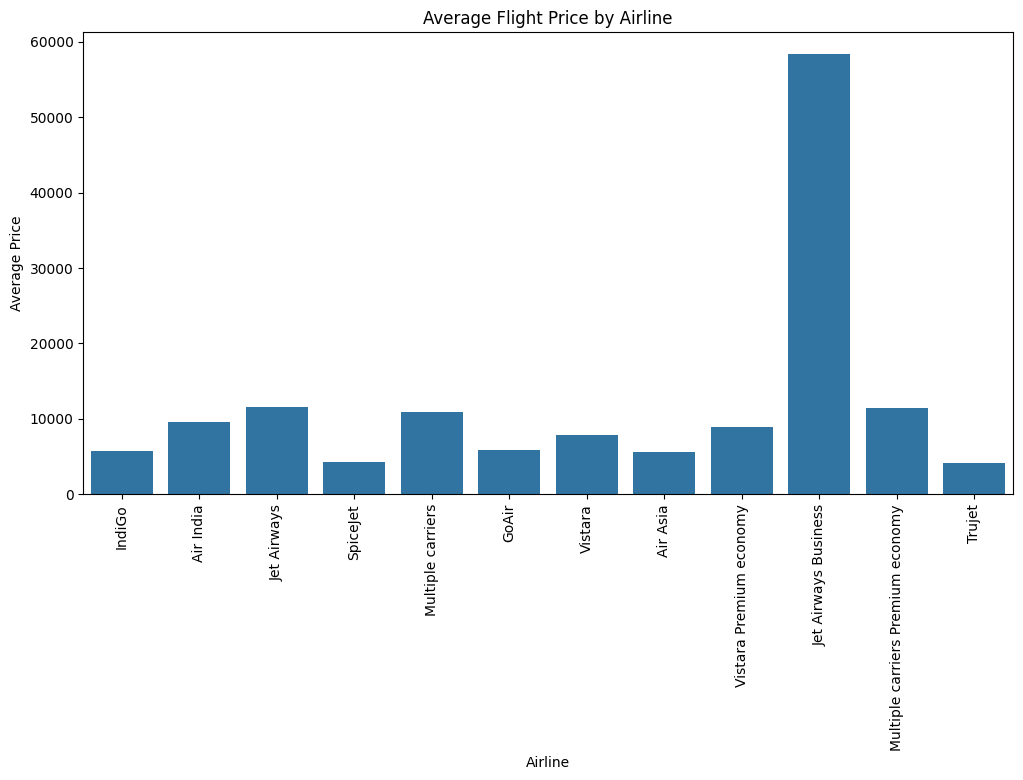

In [16]:
plt.figure(figsize=(12, 6))
sns.barplot(data=data, x='Airline', y='Price',errorbar= None)
plt.xticks(rotation=90)
plt.title('Average Flight Price by Airline')
plt.xlabel('Airline')
plt.ylabel('Average Price')
plt.show()

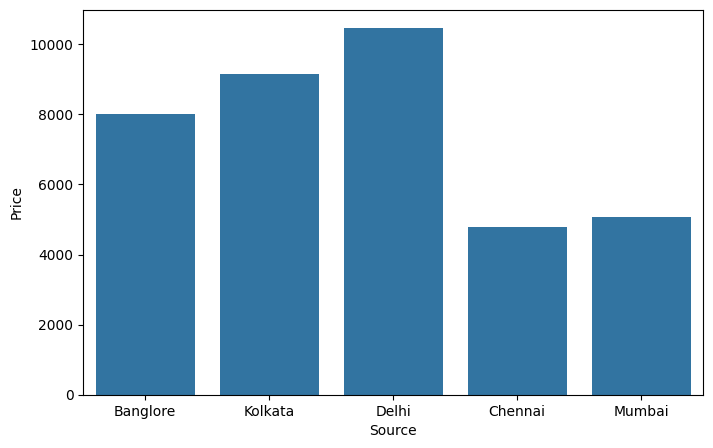

In [17]:
plt.figure(figsize=(8,5))
sns.barplot(data=data, x="Source", y="Price", errorbar=None)
plt.xlabel("Source")
plt.ylabel("Price")
plt.show()

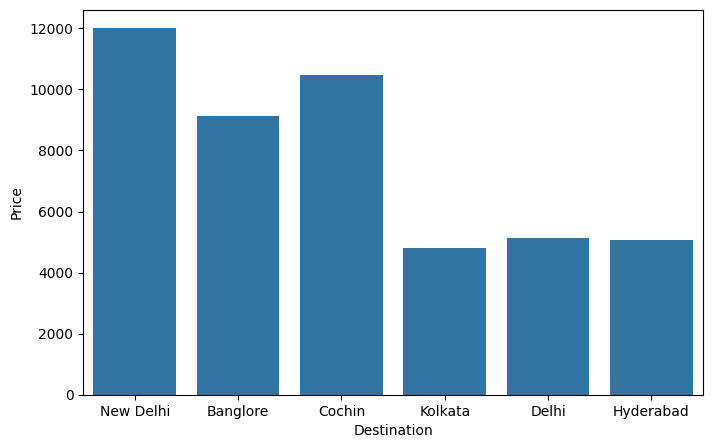

In [18]:
plt.figure(figsize=(8,5))
sns.barplot(data=data, x='Destination', y="Price", errorbar=None)
plt.xlabel("Destination")
plt.ylabel("Price")
plt.show()

## 9. Feature Engineering

In [19]:
data['Date_of_Journey'] = pd.to_datetime(data['Date_of_Journey'],format='%d/%m/%Y')

In [20]:
data['Journey_Day'] = data['Date_of_Journey'].dt.day
data['Journey_Month'] = data['Date_of_Journey'].dt.month
data['Journey_Year'] = data['Date_of_Journey'].dt.year

data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year
0,IndiGo,2019-03-24,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019
1,Air India,2019-05-01,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019
2,Jet Airways,2019-06-09,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019
3,IndiGo,2019-05-12,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019
4,IndiGo,2019-03-01,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019


In [21]:
data['Journey_Year'].unique()

array([2019], dtype=int32)

In [22]:
def convert_duration(x):
    parts = x.split()
    
    hours = 0
    minutes = 0
    
    for part in parts:
        if 'h' in part:
            hours = int(part.replace('h', ''))
        elif 'm' in part:
            minutes = int(part.replace('m', ''))
    
    return hours * 60 + minutes

In [23]:
data['Duration_Minutes'] = data['Duration'].apply(convert_duration)

In [24]:
data[['Duration', 'Duration_Minutes']].head()

,Duration,Duration_Minutes
0,2h 50m,170
1,7h 25m,445
2,19h,1140
3,5h 25m,325
4,4h 45m,285


In [25]:
data['Dep_Hour'] = data['Dep_Time'].str.split(':').str[0].astype(int)
data['Dep_Minute'] = data['Dep_Time'].str.split(':').str[1].astype(int)

In [26]:
data['Arrival_Hour'] = data['Arrival_Time'].str.split(':').str[0].astype(int)
data['Arrival_Minute'] = data['Arrival_Time'].str.split(':').str[1].str[:2].astype(int)

In [27]:
data[['Dep_Time', 'Dep_Hour', 'Dep_Minute',
      'Arrival_Time', 'Arrival_Hour', 'Arrival_Minute']].head()

,Dep_Time,Dep_Hour,Dep_Minute,Arrival_Time,Arrival_Hour,Arrival_Minute
0,22:20,22,20,01:10 22 Mar,1,10
1,05:50,5,50,13:15,13,15
2,09:25,9,25,04:25 10 Jun,4,25
3,18:05,18,5,23:30,23,30
4,16:50,16,50,21:35,21,35


In [28]:
data.drop(['Date_of_Journey', 'Journey_Year', 'Duration','Dep_Time', 'Arrival_Time'], axis=1, inplace=True)

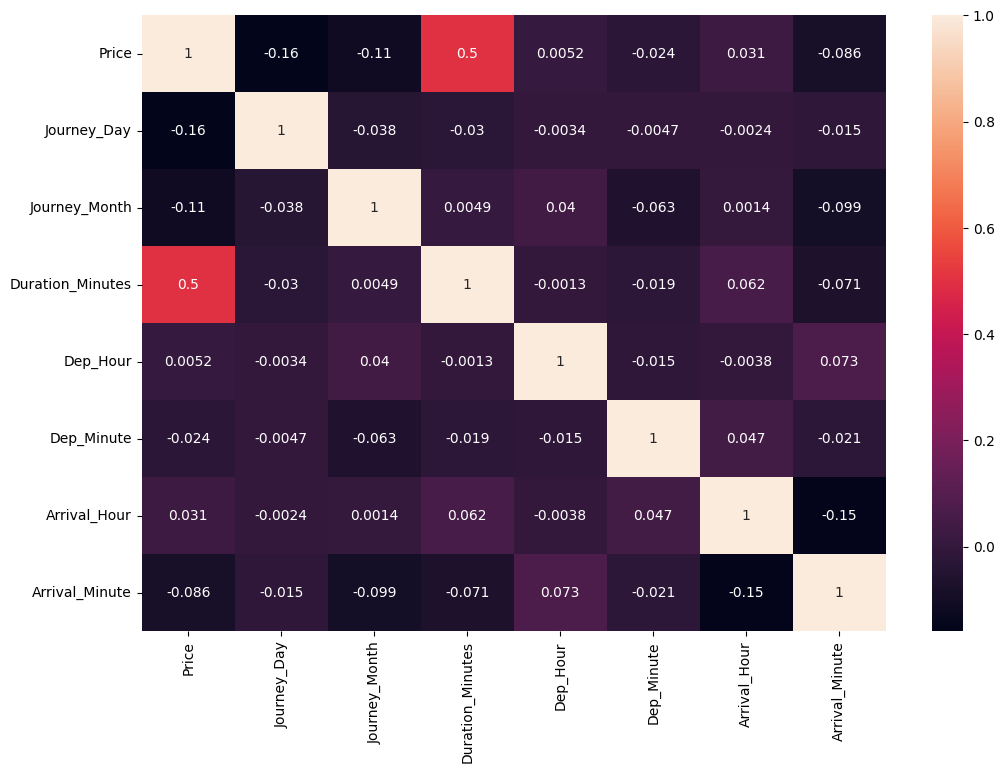

In [29]:
plt.figure(figsize=(12,8))
sns.heatmap(data.corr(numeric_only=True), annot=True)
plt.show()

<Axes: xlabel='Duration_Minutes', ylabel='Price'>

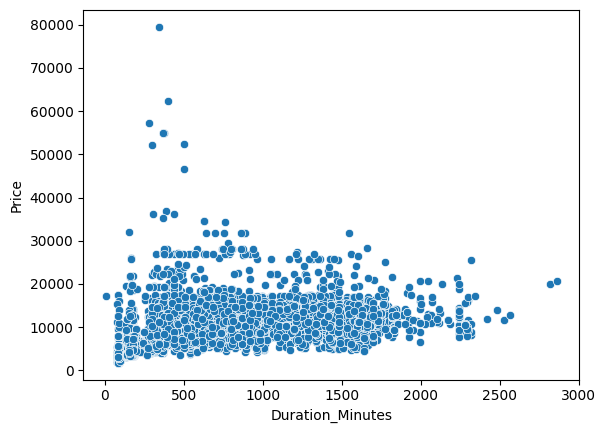

In [30]:
sns.scatterplot(data=data,x='Duration_Minutes',y='Price')

<Axes: xlabel='Journey_Month', ylabel='Price'>

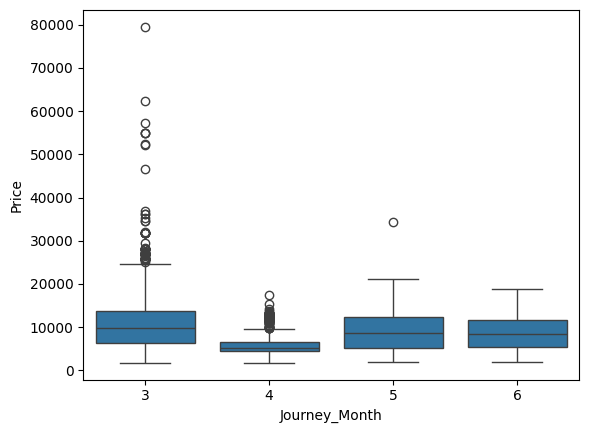

In [31]:
sns.boxplot(data=data,x='Journey_Month',y='Price')

In [32]:
data['Total_Stops'] = data['Total_Stops'].replace({
    'non-stop': 0,
    '1 stop': 1,
    '2 stops': 2,
    '3 stops': 3,
    '4 stops': 4
})

/var/folders/rs/r90vs3p52xj_8lslpq79wy_m0000gn/T/ipykernel_16472/1936951758.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['Total_Stops'] = data['Total_Stops'].replace({


In [33]:
data.value_counts('Total_Stops')

Total_Stops
1    5625
0    3475
2    1318
3      43
4       1
Name: count, dtype: int64

In [34]:
data[['Airline', 'Source', 'Destination', 'Route', 'Additional_Info']].nunique()

Airline             12
Source               5
Destination          6
Route              128
Additional_Info     10
dtype: int64

In [35]:
data.value_counts("Additional_Info")

Additional_Info
No info                         8182
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
2 Long layover                     1
Red-eye flight                     1
Name: count, dtype: int64

In [36]:
data.drop('Additional_Info', axis=1, inplace=True)

#### Additional_Info was removed because the majority of observations contain 'No info', resulting in limited useful variation.

In [37]:
data.value_counts("Airline")

Airline
Jet Airways                          3700
IndiGo                               2043
Air India                            1694
Multiple carriers                    1196
SpiceJet                              815
Vistara                               478
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

In [38]:
data = pd.get_dummies(data, columns=['Airline'], drop_first=True)

In [39]:
data.shape

(10462, 23)

In [40]:
data.value_counts("Source")

Source
Delhi       4345
Kolkata     2860
Banglore    2179
Mumbai       697
Chennai      381
Name: count, dtype: int64

In [41]:
data = pd.get_dummies(data, columns=['Source'], drop_first=True)

In [42]:
data.value_counts("Destination")

Destination
Cochin       4345
Banglore     2860
Delhi        1265
New Delhi     914
Hyderabad     697
Kolkata       381
Name: count, dtype: int64

In [43]:
data = pd.get_dummies(data, columns=['Destination'], drop_first=True)

In [44]:
data.shape

(10462, 30)

In [45]:
data['Route'].value_counts().head(20)

Route
DEL → BOM → COK          2376
BLR → DEL                1536
CCU → BOM → BLR           979
CCU → BLR                 724
BOM → HYD                 621
CCU → DEL → BLR           565
BLR → BOM → DEL           402
MAA → CCU                 381
DEL → HYD → COK           326
DEL → BLR → COK           232
DEL → COK                 213
DEL → JAI → BOM → COK     183
DEL → MAA → COK           146
DEL → AMD → BOM → COK     144
DEL → IDR → BOM → COK      90
DEL → HYD → MAA → COK      83
CCU → MAA → BLR            65
CCU → HYD → BLR            53
CCU → BBI → BLR            50
DEL → BHO → BOM → COK      48
Name: count, dtype: int64

Dropping Route rather than one-hot encoding all 128 routes. Dataset already have Source, Destination, Total_Stops, and Duration_Minutes, which capture much of the route-related information without creating 127 extra columns.

In [46]:
data.drop('Route', axis=1, inplace=True)

In [47]:
print('Final Shape of Data:',data.shape)

Final Shape of Data: (10462, 29)


## Feature Engineering

Date, duration, and time-related features were transformed into numerical variables suitable for machine learning. Categorical variables such as Airline, Source, and Destination were one-hot encoded.

Route and Additional_Info were removed because Route contains many unique categories and Additional_Info is highly imbalanced.

## 10. Train-Test Split

In [48]:
X = data.drop('Price', axis=1)
y = data['Price']

In [49]:
print(X.shape)
print(y.shape)

(10462, 28)
(10462,)


In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42
)

In [51]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(8369, 28)
(2093, 28)
(8369,)
(2093,)


## Model Evaluation

The models are evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

- MAE measures the average absolute difference between actual and predicted prices.
- RMSE gives greater weight to larger prediction errors.
- R² indicates how much variation in flight prices is explained by the model.

## 11. Baseline Model

In [52]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [53]:
y_pred_lr = model_lr.predict(X_test)

In [54]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R² Score:", r2_lr)

MAE: 1998.6393059377149
RMSE: 2945.796235704493
R² Score: 0.5838081325633985


In [55]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [56]:
y_pred_rf = model_rf.predict(X_test)

In [57]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R² Score:", r2_rf)

MAE: 1172.3764277580597
RMSE: 1965.9718392795226
R² Score: 0.8146285832002041


In [58]:
from sklearn.ensemble import GradientBoostingRegressor

model_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model_gb.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [59]:
y_pred_gb = model_gb.predict(X_test)

In [60]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("MAE:", mae_gb)
print("RMSE:", rmse_gb)
print("R² Score:", r2_gb)

MAE: 1536.422239787411
RMSE: 2267.5713806537674
R² Score: 0.7533903209164099


In [61]:
y_train_pred_rf = model_rf.predict(X_train)

mae_train_rf = mean_absolute_error(y_train, y_train_pred_rf)
rmse_train_rf = np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
r2_train_rf = r2_score(y_train, y_train_pred_rf)

print("Training MAE:", mae_train_rf)
print("Training RMSE:", rmse_train_rf)
print("Training R²:", r2_train_rf)

Training MAE: 576.5813163781958
Training RMSE: 992.1977752847346
Training R²: 0.95425040785471


In [62]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

In [63]:
from sklearn.model_selection import GridSearchCV

rf_best = RandomForestRegressor(random_state=42, n_jobs=-1)

grid_search = GridSearchCV(
    estimator=rf_best,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [10, 15, ...], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [64]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
0.8281281643680941


In [65]:
best_model = grid_search.best_estimator_

y_pred_rf_best = best_model.predict(X_test)

mae_rf_best = mean_absolute_error(y_test, y_pred_rf_best)
rmse_rf_best = np.sqrt(mean_squared_error(y_test, y_pred_rf_best))
r2_rf_best = r2_score(y_test, y_pred_rf_best)

print("MAE:", mae_rf_best)
print("RMSE:", rmse_rf_best)
print("R² Score:", r2_rf_best)

MAE: 1125.5765875112515
RMSE: 1847.8749103150167
R² Score: 0.836230387440344


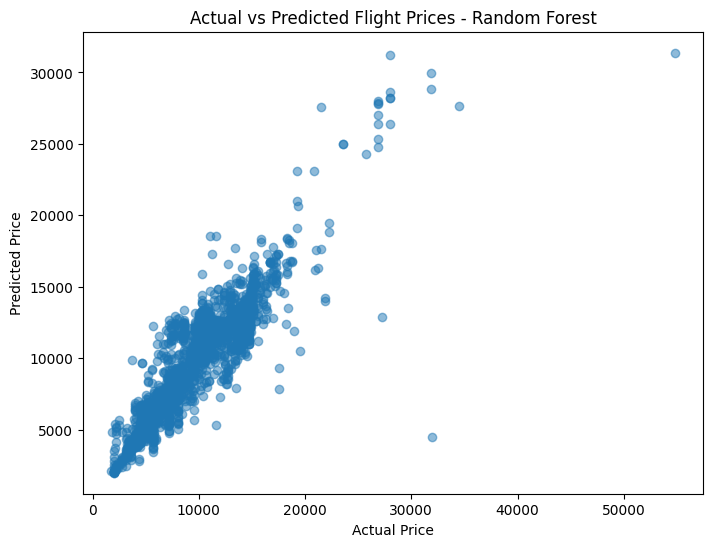

In [66]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_rf_best,
    alpha=0.5
)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Flight Prices - Random Forest')

plt.show()

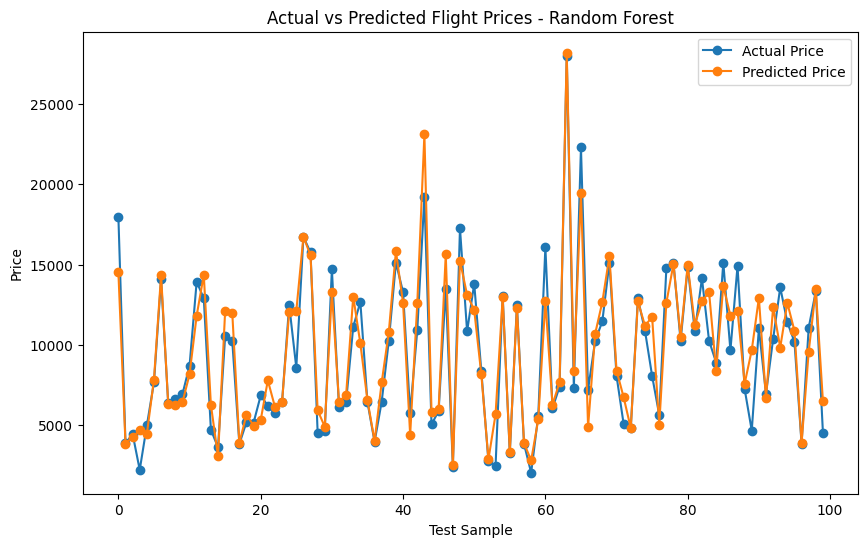

In [67]:
plt.figure(figsize=(10, 6))

plt.plot(
    y_test.values[:100],
    marker='o',
    label='Actual Price'
)

plt.plot(
    y_pred_rf_best[:100],
    marker='o',
    label='Predicted Price'
)

plt.xlabel('Test Sample')
plt.ylabel('Price')
plt.title('Actual vs Predicted Flight Prices - Random Forest')
plt.legend()

plt.show()

In [68]:
from xgboost import XGBRegressor

model_xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)

model_xgb.fit(X_train, y_train)

y_pred_xgb = model_xgb.predict(X_test)

In [69]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("MAE:", mae_xgb)
print("RMSE:", rmse_xgb)
print("R² Score:", r2_xgb)

MAE: 1254.643310546875
RMSE: 1897.462911363487
R² Score: 0.8273229002952576


In [70]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

xgb = XGBRegressor(
    random_state=42,
    objective='reg:squarederror'
)

param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid_xgb,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 54 candidates, totalling 270 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_grid,"{'learning_rate': [0.03, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [100, 200, ...], 'subsample': [0.8, 1.0]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'reg:squarederror'


In [71]:
print(grid_xgb.best_params_)
print(grid_xgb.best_score_)

{'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 200, 'subsample': 0.8}
0.8398781061172486


In [72]:
best_xgb = grid_xgb.best_estimator_

y_pred_xgb_tuned = best_xgb.predict(X_test)

mae_xgb_tuned = mean_absolute_error(y_test, y_pred_xgb_tuned)
rmse_xgb_tuned = np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuned))
r2_xgb_tuned = r2_score(y_test, y_pred_xgb_tuned)

print("MAE:", mae_xgb_tuned)
print("RMSE:", rmse_xgb_tuned)
print("R² Score:", r2_xgb_tuned)

MAE: 1159.2510986328125
RMSE: 1810.4167337936312
R² Score: 0.8428026437759399


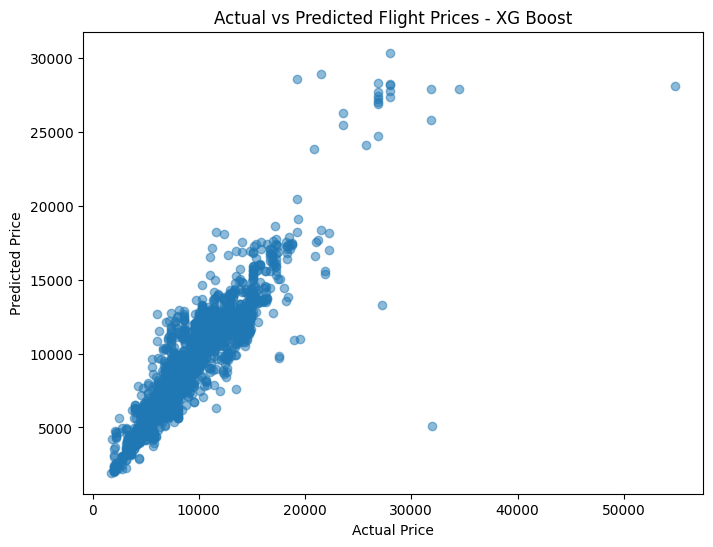

In [73]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_xgb_tuned,
    alpha=0.5
)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Flight Prices - XG Boost')

plt.show()

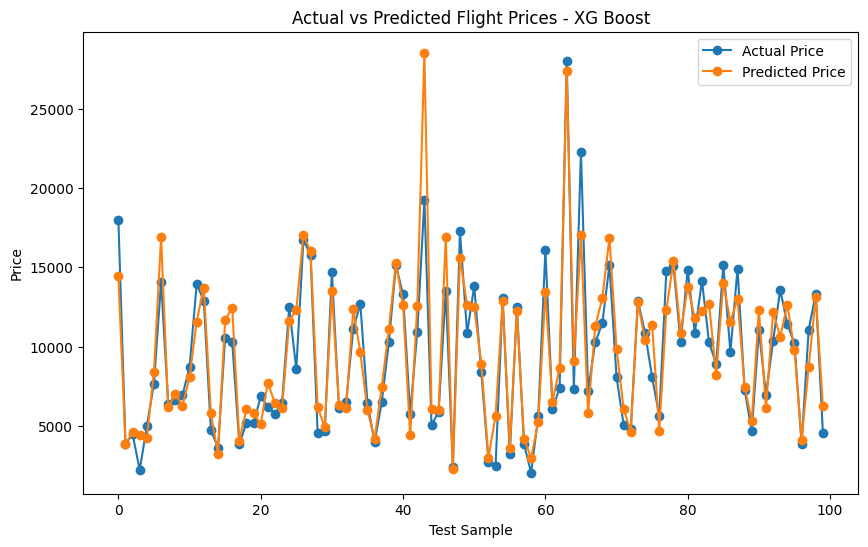

In [74]:
plt.figure(figsize=(10, 6))

plt.plot(
    y_test.values[:100],
    marker='o',
    label='Actual Price'
)

plt.plot(
    y_pred_xgb_tuned[:100],
    marker='o',
    label='Predicted Price'
)

plt.xlabel('Test Sample')
plt.ylabel('Price')
plt.title('Actual vs Predicted Flight Prices - XG Boost')
plt.legend()

plt.show()

## 12. Error Analysis

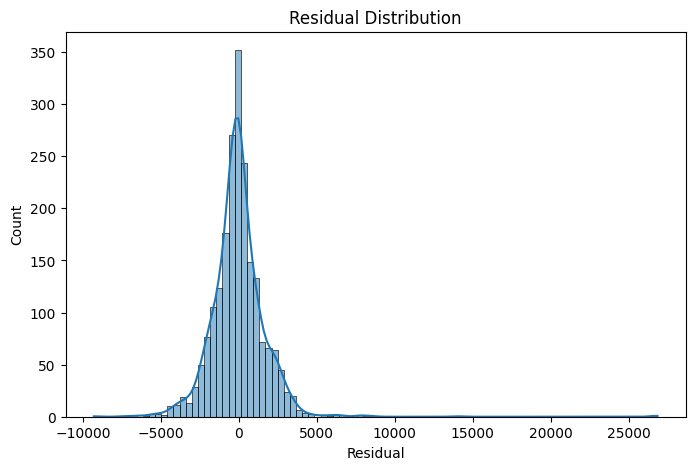

In [75]:
residuals = y_test - y_pred_xgb_tuned

plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.xlabel("Residual")
plt.title("Residual Distribution")
plt.show()

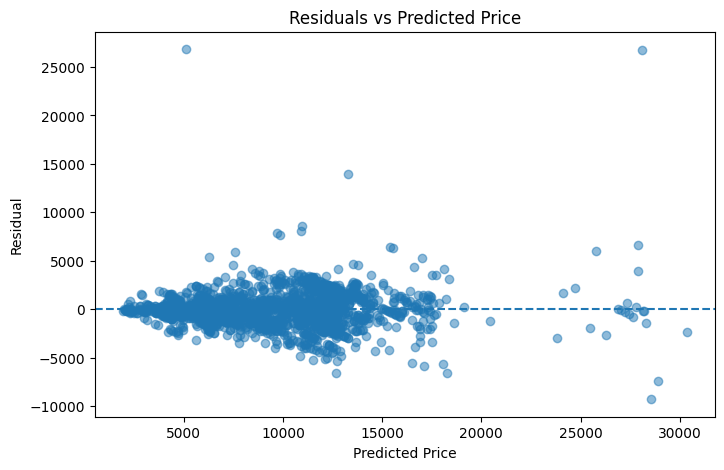

In [76]:
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_xgb_tuned, residuals, alpha=0.5)
plt.axhline(0, linestyle='--')
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Price")
plt.show()

Error Analysis Observation: The residual distribution helps assess the spread of prediction errors, while the residual-vs-predicted plot helps identify systematic patterns or changing error variance. Most predictions are centered around zero residual, although some larger errors remain for certain flight prices.

## 13. Model Comparison

## Model Comparison Summary

Six regression models were evaluated: Linear Regression, Random Forest, Gradient Boosting, XGBoost, GridSearch Random Forest, and GridSearch XGBoost.

Hyperparameter tuning was applied to Random Forest and XGBoost using GridSearchCV. The tuned models were then evaluated on the test set using the same metrics for comparison.

In [77]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting',
        'XGBoost',
        'GridSearch Random Forest',
        'GridSearch XGBoost'
    ],
    'MAE': [
        mae_lr,
        mae_rf,
        mae_gb,
        mae_xgb,
        mae_rf_best,
        mae_xgb_tuned
    ],
    'RMSE': [
        rmse_lr,
        rmse_rf,
        rmse_gb,
        rmse_xgb,
        rmse_rf_best,
        rmse_xgb_tuned
    ],
    'R2 Score': [
        r2_lr,
        r2_rf,
        r2_gb,
        r2_xgb,
        r2_rf_best,
        r2_xgb_tuned
    ]
})

model_comparison.round(3)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1998.639,2945.796,0.584
1,Random Forest,1172.376,1965.972,0.815
2,Gradient Boosting,1536.422,2267.571,0.753
3,XGBoost,1254.643,1897.463,0.827
4,GridSearch Random Forest,1125.577,1847.875,0.836
5,GridSearch XGBoost,1159.251,1810.417,0.843


## 14. Conclusion

The EDA showed that flight prices vary based on airline, number of stops, source, destination, journey date, and flight duration, with most prices concentrated at lower values and a few high-priced flights. Among the models tested, the GridSearch XGBoost model achieved the highest R² and lowest RMSE, while the GridSearch Random Forest achieved the lowest MAE. The GridSearch XGBoost model was selected as the final model because it explained slightly more variance and produced the lowest RMSE. GridSearch XGBoost achieved an MAE of ₹1,159.25, RMSE of ₹1,810.42, and R² of 0.84. The model can be used to estimate flight prices and support flight planning and fare comparison. However, the dataset is mainly from 2019, and factors such as booking time, demand, and seat availability are not included. Future improvements could include using recent data, adding more relevant features, and further tuning the model.